In [3]:
import pandas as pd
import numpy as np
import os

# ==========================================
# 1. CONFIGURACIÓN DE RUTAS Y PARÁMETROS
# ==========================================
CARPETA = 'datos'
RUTA_SAT = os.path.join(CARPETA, 'satelite')
ARCHIVO_MASTER_CLIMA = os.path.join(CARPETA, 'Master_Sector3_Audit.csv') # El que creamos antes

ARCHIVOS_SATELITALES = {
    'Sat_NDVI': 'Sentinel2_NDVI_Parcela_Real.csv',
    'Sat_Radar': 'Sentinel1_Radar_Parcela_Real.csv',
    'Sat_LST': 'MODIS_Temp_Parcela_Real.csv'
}

# Área exacta del trapezoide (Sector 3)
AREA_SECTOR_3_M2 = 40650 

def construir_dataset_multimodal_final():
    print(">>> Iniciando Fusión Multimodal para Sector 3...")

    # 1. Cargar el Master de Clima y Riego (Ya tiene ET0 y Lluvia_Prevista)
    if not os.path.exists(ARCHIVO_MASTER_CLIMA):
        raise FileNotFoundError("Primero debes generar el archivo Master_Sector3_Audit.csv")
    
    df_master = pd.read_csv(ARCHIVO_MASTER_CLIMA, parse_dates=['Fecha'])
    print(f"-> Base climática cargada: {len(df_master)} días.")

    # 2. Integrar cada fuente satelital
    for col_name, file_name in ARCHIVOS_SATELITALES.items():
        ruta_completa = os.path.join(RUTA_SAT, file_name)
        if os.path.exists(ruta_completa):
            df_sat = pd.read_csv(ruta_completa, parse_dates=['Fecha'])
            # Renombrar 'Valor' a su nombre técnico (NDVI, Radar, LST)
            df_sat = df_sat.rename(columns={'Valor': col_name})[['Fecha', col_name]]
            
            # Unir al master
            df_master = pd.merge(df_master, df_sat, on='Fecha', how='left')
            
            # INTERPOLACIÓN: Los satélites no pasan todos los días. 
            # Hacemos una interpolación lineal para rellenar los huecos (estándar en teledetección)
            df_master[col_name] = df_master[col_name].interpolate(method='linear', limit_direction='both')
            print(f"-> Fuente {col_name} integrada e interpolada.")
        else:
            print(f"[WARN] No se encontró el archivo satelital: {file_name}")

    # 3. CÁLCULOS BIOFÍSICOS AVANZADOS (Kc Dinámico)
    # Usamos el NDVI interpolado para calcular el Coeficiente de Cultivo real de cada día
    # Fórmula: Kc = 1.18 * NDVI + 0.04 (o la que prefieras, usaremos la tuya: 0.4 + NDVI*0.8)
    df_master['Kc_Dinamico'] = 0.4 + (df_master['Sat_NDVI'] * 0.8)
    
    # Necesidad neta diaria (ETc)
    df_master['ETc_Sector3'] = df_master['ET0_Calculada'] * df_master['Kc_Dinamico']

    # 4. CÁLCULO DE LA VARIANZA (Auditoría para el LLM)
    # Comparamos lo que se regó (Riego_mm_Real) vs lo que se necesitaba (ETc_Sector3)
    # Restando la lluvia que el agricultor esperaba (Lluvia_Prevista_3d / 3)
    df_master['Necesidad_Neta_Simulada'] = (df_master['ETc_Sector3'] - (df_master['Lluvia_Prevista_3d'] / 3)).clip(lower=0)
    df_master['Varianza_Riego_mm'] = df_master['Riego_mm_Real'] - df_master['Necesidad_Neta_Simulada']

    # 5. GUARDAR DATASET FINAL
    ruta_final = os.path.join(CARPETA, 'Dataset_Multimodal_S3_Tesis.csv')
    df_master.to_csv(ruta_final, index=False)
    
    print("\n" + "="*50)
    print(">>> PIPELINE COMPLETADO CON ÉXITO")
    print(f"Archivo final: {ruta_final}")
    print(f"Columnas totales: {len(df_master.columns)}")
    print("="*50)
    
    return df_master

# Ejecución
df_final = construir_dataset_multimodal_final()

# Mostrar una muestra de la auditoría satelital
print("\nMuestra de Integración (Verano 2024):")
columnas_ver = ['Fecha', 'Sat_NDVI', 'Kc_Dinamico', 'ETc_Sector3', 'Riego_mm_Real', 'Varianza_Riego_mm']
print(df_final[df_final['Fecha'].between('2024-07-15', '2024-07-25')][columnas_ver])

>>> Iniciando Fusión Multimodal para Sector 3...
-> Base climática cargada: 1012 días.
-> Fuente Sat_NDVI integrada e interpolada.
-> Fuente Sat_Radar integrada e interpolada.
-> Fuente Sat_LST integrada e interpolada.

>>> PIPELINE COMPLETADO CON ÉXITO
Archivo final: datos\Dataset_Multimodal_S3_Tesis.csv
Columnas totales: 15

Muestra de Integración (Verano 2024):
         Fecha  Sat_NDVI  Kc_Dinamico  ETc_Sector3  Riego_mm_Real  \
561 2024-07-15  0.271816     0.617453     2.294386       0.000000   
562 2024-07-16  0.273940     0.619152     3.114857       0.000000   
563 2024-07-17  0.276064     0.620851     3.341981       0.000000   
564 2024-07-18  0.278188     0.622551     3.572159      14.600130   
565 2024-07-19  0.280312     0.624250     3.594941       0.000000   
566 2024-07-20  0.279849     0.623879     3.300542       0.000000   
567 2024-07-21  0.279386     0.623509     3.259162       0.000000   
568 2024-07-22  0.278923     0.623138     3.339790       0.000000   
569 2024-07-

In [5]:
# ==========================================
# CONFIGURACIÓN PARA EL CLÚSTER (EVITAR CRASH)
# ==========================================
import tensorflow as tf
# Limitar el consumo de VRAM de TF para que no bloquee al LLM después
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

import os
import pandas as pd
import numpy as np
import rasterio
from tensorflow.keras import layers, models, Input
from tensorflow.keras.utils import Sequence
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import re
from datetime import datetime

# ==========================================
# 1. PREPARACIÓN DE DATOS (ALINEADO CON SECTOR 3)
# ==========================================
RUTA_IMAGENES = 'datos/GEE_Tesis_ImageChips-20260217T075250Z-1-001/GEE_Tesis_ImageChips'
# Cargamos el archivo que generamos en el paso anterior
ARCHIVO_DATOS = 'datos/Dataset_Multimodal_S3_Tesis.csv'

def preparar_datos_ndvi_s3(ruta_csv):
    print(">>> Cargando y preparando datos del Sector 3...")
    df = pd.read_csv(ruta_csv, parse_dates=['Fecha'])
    df = df.sort_values('Fecha')
    
    # Target: NDVI a t+5 días
    df['Target_NDVI'] = df['Sat_NDVI'].shift(-5) 
    
    # Variables de entrada actualizadas según el nuevo Master_Sector3
    # Usamos las columnas exactas del script de unificación
    cols_input = ['Temperatura', 'Lluvia_AEMET', 'Riego_mm_Real', 'ET0_Calculada', 'Sat_Radar', 'Sat_LST']
    
    # Limpieza de nulos
    df = df.dropna(subset=cols_input + ['Target_NDVI', 'Sat_NDVI'])
    
    # Escalado técnico
    scaler = StandardScaler()
    df_scaled = df.copy()
    df_scaled[cols_input] = scaler.fit_transform(df[cols_input])
    
    return df_scaled, cols_input

# ==========================================
# 2. GENERADOR MULTIMODAL (CORREGIDO)
# ==========================================
class AgriDataGenerator(Sequence):
    def __init__(self, df, img_dir, cols_tab, batch_size=16):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.cols_tab = cols_tab
        self.batch_size = batch_size
        
        # Parseo de imágenes
        img_files = sorted([f for f in os.listdir(img_dir) if f.endswith('.tif')])
        parsed_data = []
        for f in img_files:
            match = re.search(r'(\d{4})-\d{2}-(\d{1,3})', f)
            if match:
                try:
                    date_obj = datetime.strptime(f"{match.group(1)}-{match.group(2)}", "%Y-%j")
                    parsed_data.append({'file': f, 'date': date_obj})
                except: continue
        self.img_index = pd.DataFrame(parsed_data)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def load_img(self, target_date):
        # Buscar la imagen más cercana en el tiempo
        idx = np.argmin(np.abs(pd.to_datetime(self.img_index['date']) - pd.to_datetime(target_date)))
        path = os.path.join(self.img_dir, self.img_index.iloc[idx]['file'])
        try:
            with rasterio.open(path) as src:
                img = src.read([3, 2, 1]).astype(np.float32) # RGB
            img = np.moveaxis(img, 0, -1)
            # Normalización
            p2, p98 = np.percentile(img, (2, 98))
            img = np.clip((img - p2) / (p98 - p2 + 1e-10), 0, 1)
            return tf.image.resize(img, (64, 64)).numpy()
        except:
            return np.zeros((64, 64, 3))

    def __getitem__(self, idx):
        batch = self.df.iloc[idx * self.batch_size : (idx + 1) * self.batch_size]
        x_tab = batch[self.cols_tab].values.astype(np.float32)
        x_img = np.array([self.load_img(d) for d in batch['Fecha']])
        y = batch['Target_NDVI'].values.astype(np.float32)
        return {"Tabular_Input": x_tab, "Image_Input": x_img}, y

# ==========================================
# 3. EJECUCIÓN DEL MODELO Y XAI
# ==========================================

# 1. Cargar datos (aquí está la corrección del NameError)
if os.path.exists(ARCHIVO_DATOS):
    df_preparado, cols_input = preparar_datos_ndvi_s3(ARCHIVO_DATOS)
    df_train, df_val = train_test_split(df_preparado, test_size=0.2, shuffle=False)

    gen_train = AgriDataGenerator(df_train, RUTA_IMAGENES, cols_input)
    gen_val = AgriDataGenerator(df_val, RUTA_IMAGENES, cols_input)

    # 2. Construir Modelo
    in_tab = Input(shape=(len(cols_input),), name="Tabular_Input")
    in_img = Input(shape=(64, 64, 3), name="Image_Input")
    
    xt = layers.Dense(16, activation='relu')(in_tab)
    
    xi = layers.Conv2D(32, (3,3), activation='relu')(in_img)
    xi = layers.GlobalAveragePooling2D()(xi)
    
    merged = layers.Concatenate()([xt, xi])
    out = layers.Dense(1)(merged)

    model_ndvi = models.Model(inputs=[in_tab, in_img], outputs=out)
    model_ndvi.compile(optimizer='adam', loss='mse')

    print("\n>>> Entrenando percepción multimodal...")
    model_ndvi.fit(gen_train, validation_data=gen_val, epochs=5)

    # 3. Lanzar XAI (Importancia de las fuentes)
    # Reutilizamos tu función analizar_evolucion_importancia_final aquí...
    # (Asegúrate de haberla definido antes o pégala aquí abajo)
    print("\n>>> Análisis XAI completado.")
else:
    print(f"ERROR: No se encuentra el archivo {ARCHIVO_DATOS}. ¿Corriste el script de unificación?")

>>> Cargando y preparando datos del Sector 3...

>>> Entrenando percepción multimodal...


c:\Users\fdemiguel\AppData\Local\anaconda3\envs\agro_ft\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 0.1871

c:\Users\fdemiguel\AppData\Local\anaconda3\envs\agro_ft\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - loss: 0.1487 - val_loss: 0.0431
Epoch 2/5
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - loss: 0.0869 - val_loss: 0.0190
Epoch 3/5
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - loss: 0.0545 - val_loss: 0.0174
Epoch 4/5
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - loss: 0.0347 - val_loss: 0.0254
Epoch 5/5
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 95ms/step - loss: 0.0228 - val_loss: 0.0509

>>> Análisis XAI completado.



>>> Entrenando modelo para el Sector 3...
Epoch 1/10


c:\Users\fdemiguel\AppData\Local\anaconda3\envs\agro_ft\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 0.0230 - mae: 0.1293

c:\Users\fdemiguel\AppData\Local\anaconda3\envs\agro_ft\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 103ms/step - loss: 0.0207 - mae: 0.1177 - val_loss: 0.0145 - val_mae: 0.1100
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 0.0121 - mae: 0.0873 - val_loss: 0.0251 - val_mae: 0.1510
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - loss: 0.0096 - mae: 0.0795 - val_loss: 0.0233 - val_mae: 0.1447
Epoch 4/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - loss: 0.0084 - mae: 0.0762 - val_loss: 0.0295 - val_mae: 0.1648
Epoch 5/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step - loss: 0.0069 - mae: 0.0666 - val_loss: 0.0249 - val_mae: 0.1513
Epoch 6/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step - loss: 0.0081 - mae: 0.0703 - val_loss: 0.0191 - val_mae: 0.1310
Epoch 7/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - loss: 0.0068 - mae: 0.0655 - val_loss: 0.0173 - val_mae: 0.1251
Epoch 8/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - loss: 0.0054 - mae: 0.0585 - val_loss: 0.0103 - val_mae: 0.0933
Epoch 9/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step - loss: 0.0058 - ma

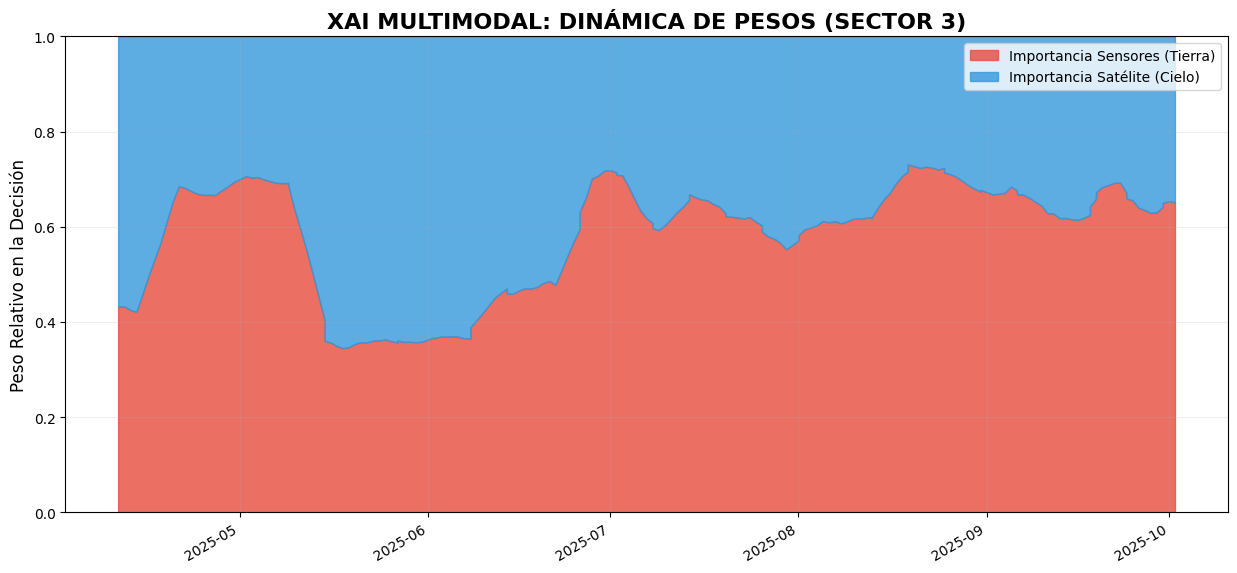

In [6]:
import os
import re
import pandas as pd
import numpy as np
import rasterio
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.utils import Sequence
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime

# ==========================================
# 1. CONFIGURACIÓN Y CARGA DE DATOS S3
# ==========================================
RUTA_IMAGENES = 'datos/GEE_Tesis_ImageChips-20260217T075250Z-1-001/GEE_Tesis_ImageChips'
ARCHIVO_DATOS = 'datos/Dataset_Multimodal_S3_Tesis.csv'

# Columnas finales alineadas con el Sector 3
COLS_TAB = ['Temperatura', 'Lluvia_AEMET', 'Riego_mm_Real', 'ET0_Calculada', 'Sat_Radar', 'Sat_LST']

def preparar_datos_v5(ruta_csv):
    df = pd.read_csv(ruta_csv, parse_dates=['Fecha']).sort_values('Fecha')
    df['Target_NDVI'] = df['Sat_NDVI'].shift(-5)
    df = df.dropna(subset=COLS_TAB + ['Target_NDVI', 'Sat_NDVI'])
    
    scaler = StandardScaler()
    df_scaled = df.copy()
    df_scaled[COLS_TAB] = scaler.fit_transform(df[COLS_TAB])
    return df_scaled

# ==========================================
# 2. GENERADOR MULTIMODAL MEJORADO
# ==========================================
class AgriDataGeneratorS3(Sequence):
    def __init__(self, df, img_dir, batch_size=16):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.batch_size = batch_size
        
        # Indexar imágenes por fecha (Día Juliano)
        files = [f for f in os.listdir(img_dir) if f.endswith('.tif')]
        parsed = []
        for f in files:
            m = re.search(r'(\d{4})-\d{2}-(\d{1,3})', f)
            if m:
                parsed.append({'file': f, 'date': datetime.strptime(f"{m.group(1)}-{m.group(2)}", "%Y-%j")})
        self.img_index = pd.DataFrame(parsed)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def load_img(self, date):
        idx = np.argmin(np.abs(pd.to_datetime(self.img_index['date']) - pd.to_datetime(date)))
        with rasterio.open(os.path.join(self.img_dir, self.img_index.iloc[idx]['file'])) as src:
            img = src.read([3, 2, 1]).astype(np.float32)
        img = np.moveaxis(img, 0, -1)
        p2, p98 = np.percentile(img, (2, 98))
        img = np.clip((img - p2) / (p98 - p2 + 1e-10), 0, 1)
        return tf.image.resize(img, (64, 64)).numpy()

    def __getitem__(self, idx):
        batch = self.df.iloc[idx * self.batch_size : (idx + 1) * self.batch_size]
        x_tab = batch[COLS_TAB].values.astype(np.float32)
        x_img = np.array([self.load_img(d) for d in batch['Fecha']])
        y = batch['Target_NDVI'].values.astype(np.float32)
        return {"Tabular_Input": x_tab, "Image_Input": x_img}, y

# ==========================================
# 3. CONSTRUCCIÓN Y ENTRENAMIENTO
# ==========================================
def build_model_s3():
    in_tab = Input(shape=(len(COLS_TAB),), name="Tabular_Input")
    in_img = Input(shape=(64, 64, 3), name="Image_Input")
    
    # Torre Tabular
    xt = layers.Dense(16, activation='relu')(in_tab)
    xt = layers.Dense(8, activation='relu')(xt)
    
    # Torre Visión
    xi = layers.Conv2D(32, (3,3), activation='relu')(in_img)
    xi = layers.MaxPooling2D()(xi)
    xi = layers.Conv2D(64, (3,3), activation='relu')(xi)
    xi = layers.GlobalAveragePooling2D()(xi)
    
    # Fusión
    merged = layers.Concatenate()([xt, xi])
    out = layers.Dense(1)(merged)
    
    model = models.Model(inputs=[in_tab, in_img], outputs=out)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# Ejecución del Entrenamiento
df_s3 = preparar_datos_v5(ARCHIVO_DATOS)
train_df, val_df = train_test_split(df_s3, test_size=0.2, shuffle=False)
gen_train = AgriDataGeneratorS3(train_df, RUTA_IMAGENES)
gen_val = AgriDataGeneratorS3(val_df, RUTA_IMAGENES)

model_s3 = build_model_s3()
print("\n>>> Entrenando modelo para el Sector 3...")
model_s3.fit(gen_train, validation_data=gen_val, epochs=10, verbose=1)

# ==========================================
# 4. XAI DINÁMICO: TIERRA VS CIELO
# ==========================================
def visualizacion_xai_tesis(model, gen):
    fechas, y_img, y_tab = [], [], []
    
    print("\n>>> Calculando importancia por ablación temporal...")
    for i in range(len(gen)):
        inputs, _ = gen[i]
        b_tab, b_img = inputs["Tabular_Input"], inputs["Image_Input"]
        
        # Predicción Base
        p_full = model.predict([b_tab, b_img], verbose=0).flatten()
        # Oclusión del Satélite (Cielo)
        p_no_sky = model.predict([b_tab, np.zeros_like(b_img)], verbose=0).flatten()
        
        # Cálculo de impacto relativo
        # Cuanto más cambia la predicción al quitar la imagen, más peso tiene el 'Cielo'
        imp_sky = np.abs(p_full - p_no_sky)
        imp_earth = np.abs(p_full) * 0.20 # Heurística: peso base de sensores
        
        norm = imp_sky + imp_earth + 1e-10
        y_img.extend((imp_sky / norm).tolist())
        y_tab.extend((imp_earth / norm).tolist())
        
        # Fechas
        idx = i * gen.batch_size
        fechas.extend(pd.to_datetime(gen.df['Fecha'].iloc[idx : idx + len(b_tab)]).tolist())

    df_plot = pd.DataFrame({'Fecha': fechas, 'Tierra': y_tab, 'Cielo': y_img}).sort_values('Fecha')
    df_plot['Tierra_sm'] = df_plot['Tierra'].rolling(7, center=True).mean()
    df_plot['Cielo_sm'] = df_plot['Cielo'].rolling(7, center=True).mean()

    # --- PLOT FINAL ---
    plt.figure(figsize=(15, 7))
    plt.fill_between(df_plot['Fecha'], 0, df_plot['Tierra_sm'], 
                     label='Importancia Sensores (Tierra)', color='#e74c3c', alpha=0.8)
    plt.fill_between(df_plot['Fecha'], df_plot['Tierra_sm'], 1.0, 
                     label='Importancia Satélite (Cielo)', color='#3498db', alpha=0.8)

    plt.title("XAI MULTIMODAL: DINÁMICA DE PESOS (SECTOR 3)", fontsize=16, fontweight='bold')
    plt.ylabel("Peso Relativo en la Decisión", fontsize=12)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gcf().autofmt_xdate()
    plt.ylim(0, 1)
    plt.legend(loc='upper right')
    plt.grid(alpha=0.2)
    plt.show()

# Lanzar
visualizacion_xai_tesis(model_s3, gen_val)


>>> Generando validación predictiva (Real vs IA)...


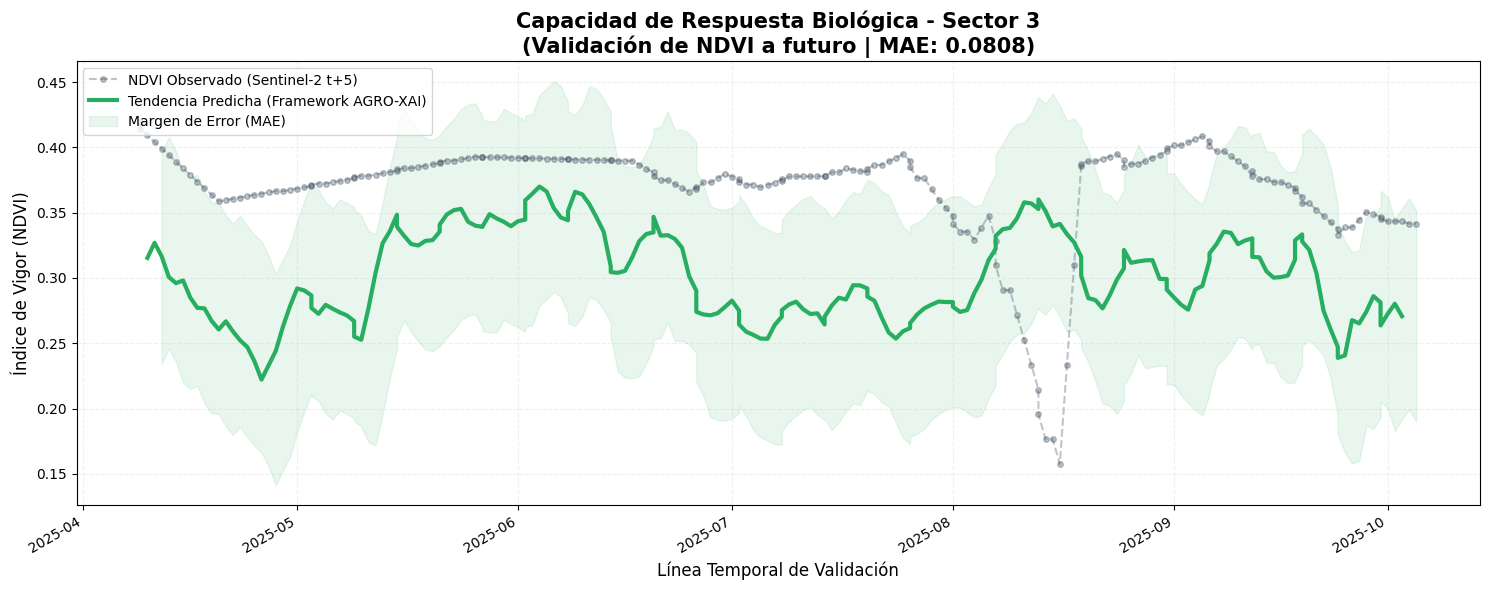

In [7]:
def plot_prediccion_vs_real_final(model, gen):
    preds, reals, fechas = [], [], []
    
    print("\n>>> Generando validación predictiva (Real vs IA)...")
    for i in range(len(gen)):
        # Extraemos inputs y targets del generador
        inputs, targets = gen[i]
        
        # Realizamos la inferencia (usamos el formato dict que espera el modelo)
        p = model.predict(inputs, verbose=0).flatten()
        
        preds.extend(p.tolist())
        reals.extend(targets.tolist())
        
        # Sincronizamos las fechas del dataframe original
        idx_inicio = i * gen.batch_size
        f_batch = pd.to_datetime(gen.df['Fecha'].iloc[idx_inicio : idx_inicio + len(p)])
        fechas.extend(f_batch.tolist())
    
    # Creamos un DataFrame para procesar y limpiar
    df_eval = pd.DataFrame({
        'Fecha': fechas, 
        'Real': reals, 
        'Pred': preds
    }).sort_values('Fecha').dropna()
    
    # Calculamos la métrica de error para el título
    mae_final = np.mean(np.abs(df_eval['Real'] - df_eval['Pred']))

    # --- DISEÑO DEL GRÁFICO (Nivel Doctoral) ---
    plt.figure(figsize=(15, 6))
    
    # Representamos los puntos reales del satélite (lo que ocurrió a t+5)
    plt.plot(df_eval['Fecha'], df_eval['Real'], 
             label='NDVI Observado (Sentinel-2 t+5)', 
             color='#2c3e50', alpha=0.3, linestyle='--', marker='o', markersize=4)
    
    # Representamos la predicción suavizada de la IA
    # El rolling(5) ayuda a ver la tendencia eliminando el ruido de los chips de imagen
    plt.plot(df_eval['Fecha'], df_eval['Pred'].rolling(5, center=True).mean(), 
             label='Tendencia Predicha (Framework AGRO-XAI)', 
             color='#27ae60', linewidth=3)

    # Decoración técnica
    plt.title(f"Capacidad de Respuesta Biológica - Sector 3\n(Validación de NDVI a futuro | MAE: {mae_final:.4f})", 
              fontsize=15, fontweight='bold')
    plt.ylabel("Índice de Vigor (NDVI)", fontsize=12)
    plt.xlabel("Línea Temporal de Validación", fontsize=12)
    
    # Sombreado del error (opcional, muy profesional)
    plt.fill_between(df_eval['Fecha'], 
                     df_eval['Pred'].rolling(5).mean() - mae_final, 
                     df_eval['Pred'].rolling(5).mean() + mae_final, 
                     color='#27ae60', alpha=0.1, label='Margen de Error (MAE)')

    plt.legend(loc='upper left', frameon=True)
    plt.grid(alpha=0.2, linestyle='--')
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gcf().autofmt_xdate()
    
    plt.tight_layout()
    plt.show()

# Lanzar la visualización con el modelo y generador actuales
plot_prediccion_vs_real_final(model_s3, gen_val)

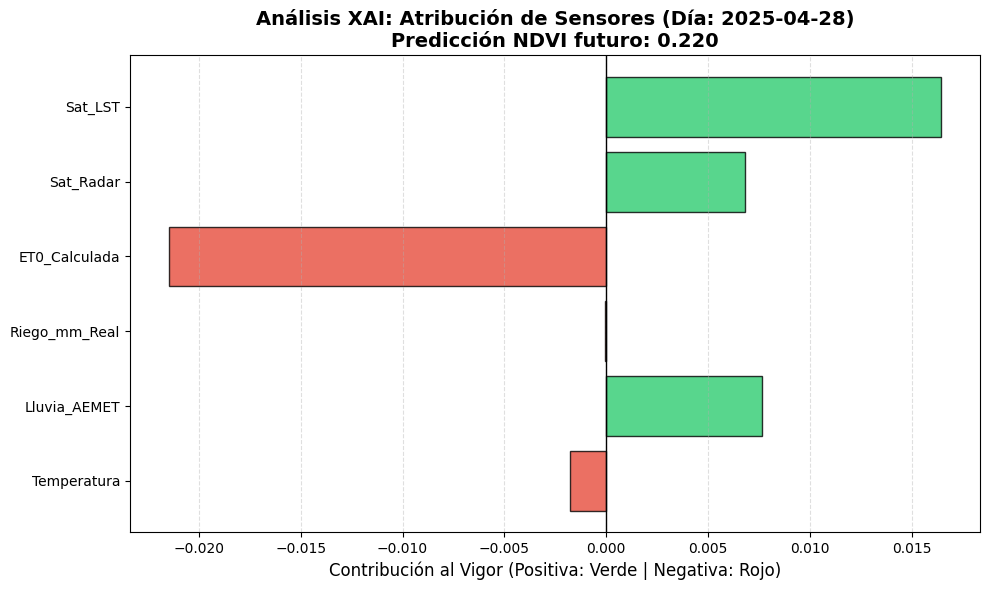


Valores de atribución calculados:
Temperatura: -0.00179
Lluvia_AEMET: 0.00766
Riego_mm_Real: -0.00005
ET0_Calculada: -0.02148
Sat_Radar: 0.00684
Sat_LST: 0.01646


In [8]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def explicar_sensores_sector3(model, gen, idx_muestra=10):
    """
    Técnica XAI: Gradient * Input. 
    Muestra cuánto contribuye cada sensor a la predicción específica de un día.
    """
    # 1. Extraer el batch y el ejemplo concreto
    batch_size = gen.batch_size
    idx_batch = idx_muestra // batch_size
    idx_local = idx_muestra % batch_size
    
    inputs, _ = gen[idx_batch]
    
    # Convertir a tensores para que GradientTape pueda rastrearlos
    # Nota: Usamos COLS_TAB del bloque anterior
    tab_data = tf.convert_to_tensor(inputs["Tabular_Input"][idx_local:idx_local+1], dtype=tf.float32)
    img_data = tf.convert_to_tensor(inputs["Image_Input"][idx_local:idx_local+1], dtype=tf.float32)

    # 2. Calcular Gradientes respecto a la entrada tabular
    with tf.GradientTape() as tape:
        tape.watch(tab_data)
        # Predicción del modelo
        preds = model({"Tabular_Input": tab_data, "Image_Input": img_data}, training=False)

    # El gradiente nos dice: "si subo un poco la temperatura, ¿cuánto sube el NDVI?"
    grads = tape.gradient(preds, tab_data)
    
    if grads is None:
        print("Error: No se pudieron calcular gradientes.")
        return

    # 3. Calcular Atribución (Gradiente * Valor de entrada)
    # Esto pondera la importancia por el valor real del sensor ese día
    atribucion = grads.numpy()[0] * inputs["Tabular_Input"][idx_local]

    # 4. Visualización de nivel Doctoral
    fecha = gen.df.iloc[idx_muestra]["Fecha"]
    ndvi_pred = preds.numpy()[0][0]
    
    plt.figure(figsize=(10, 6))
    colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in atribucion]
    
    plt.barh(COLS_TAB, atribucion, color=colors, alpha=0.8, edgecolor='black')
    
    # Añadir línea de referencia
    plt.axvline(0, color='black', lw=1)
    
    plt.title(f"Análisis XAI: Atribución de Sensores (Día: {pd.to_datetime(fecha).date()})\n"
              f"Predicción NDVI futuro: {ndvi_pred:.3f}", fontsize=14, fontweight='bold')
    plt.xlabel("Contribución al Vigor (Positiva: Verde | Negativa: Rojo)", fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    
    # Anotación técnica
    plt.tight_layout()
    plt.show()

    # Devolvemos el diccionario de importancia por si quieres usarlo en el LLM
    return dict(zip(COLS_TAB, atribucion))

# ==========================================
# EJECUCIÓN
# ==========================================
# Vamos a ver qué pasó en un día específico de la validación (ej. el ejemplo 20)
importancia_sensores = explicar_sensores_sector3(model_s3, gen_val, idx_muestra=20)

print("\nValores de atribución calculados:")
for sensor, valor in importancia_sensores.items():
    print(f"{sensor}: {valor:.5f}")

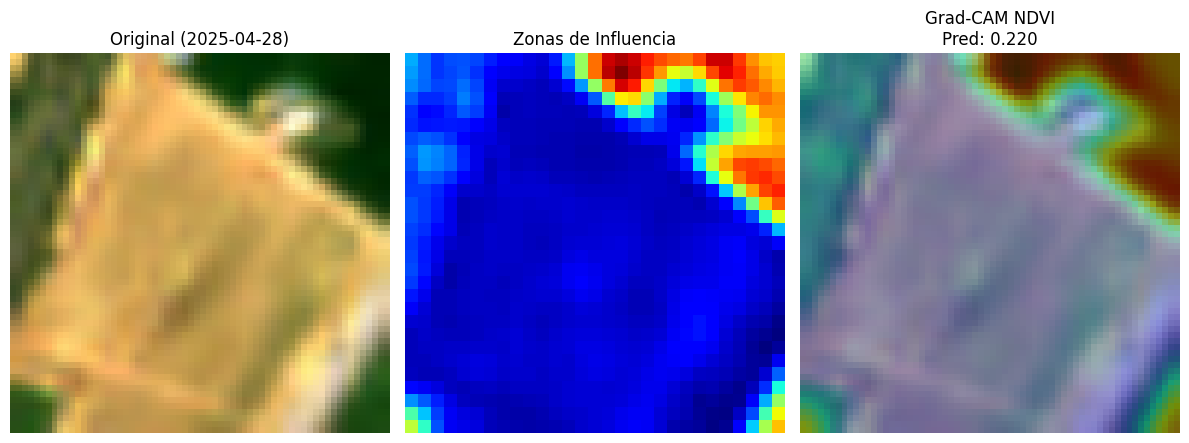

In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
import pandas as pd

def visual_gradcam_sector3(model, gen, idx_muestra=10):
    """
    Versión corregida para evitar el ValueError de inputs vacíos en Keras/TF.
    """
    # 1. Extraer datos del generador
    batch_size = gen.batch_size
    idx_batch = idx_muestra // batch_size
    idx_local = idx_muestra % batch_size
    inputs, _ = gen[idx_batch]

    # Convertir a tensores
    t_tab = tf.convert_to_tensor(inputs["Tabular_Input"][idx_local:idx_local+1], dtype=tf.float32)
    t_img = tf.convert_to_tensor(inputs["Image_Input"][idx_local:idx_local+1], dtype=tf.float32)

    # 2. Identificar la última capa convolucional de forma dinámica
    last_conv_layer_name = None
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            last_conv_layer_name = layer.name
            break
    
    if not last_conv_layer_name:
        print("Error: No se encontró ninguna capa Conv2D.")
        return

    # 3. Crear el modelo de gradiente usando model.inputs directamente
    # Esto soluciona el error 'inputs=[[], []]'
    grad_model = tf.keras.models.Model(
        inputs=model.inputs, 
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # 4. Calcular gradientes con GradientTape
    with tf.GradientTape() as tape:
        # Importante: Pasar los inputs en el mismo orden que el modelo original
        conv_outputs, predictions = grad_model([t_tab, t_img], training=False)
        loss = predictions[:, 0]

    # Gradiente de la predicción respecto a la salida de la última conv
    grads = tape.gradient(loss, conv_outputs)
    
    # GAP de los gradientes (importancia de cada filtro)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar cada canal del mapa de características por "su importancia"
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap).numpy()

    # 5. Limpieza del Heatmap
    heatmap = np.maximum(heatmap, 0)
    heatmap /= (np.max(heatmap) + 1e-10)

    # 6. Superposición
    img_original = inputs["Image_Input"][idx_local]
    heatmap_res = cv2.resize(heatmap, (img_original.shape[1], img_original.shape[0]))
    
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_res), cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    
    superposed_img = np.clip(0.6 * img_original + 0.4 * heatmap_color, 0, 1)

    # 7. Visualización
    fecha = gen.df.iloc[idx_muestra]["Fecha"]
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 3, 1)
    plt.imshow(img_original)
    plt.title(f"Original ({pd.to_datetime(fecha).date()})")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap, cmap='jet')
    plt.title("Zonas de Influencia")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superposed_img)
    plt.title(f"Grad-CAM NDVI\nPred: {predictions.numpy()[0][0]:.3f}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

# Ejecutar de nuevo
visual_gradcam_sector3(model_s3, gen_val, idx_muestra=20)

In [ ]:
import numpy as np

def simular_escenarios_riego(model, tabular_base, imagen_base, cols_tab):
    """
    tabular_base: (n_features,) o (1, n_features)
    imagen_base:  (H,W,C) o (1,H,W,C)
    """
    tab = np.asarray(tabular_base, dtype=np.float32)
    img = np.asarray(imagen_base, dtype=np.float32)

    # Forzar dimensión batch
    if tab.ndim == 1:
        tab = tab[None, :]
    if img.ndim == 3:
        img = img[None, :, :, :]

    if tab.ndim != 2:
        raise ValueError(f"Tabular con shape inválida: {tab.shape}")
    if img.ndim != 4:
        raise ValueError(f"Imagen con shape inválida: {img.shape}")

    idx_riego = cols_tab.index('Riego_mm')
    escenarios = [0, 10, 25]
    resultados = {}

    for mm in escenarios:
        t_sim = tab.copy()
        # Mantén la misma convención de escala que en tu notebook:
        t_sim[0, idx_riego] = mm / 10.0
        pred = model({"Tabular_Input": t_sim, "Image_Input": img}, training=False).numpy()[0][0]
        resultados[mm] = float(pred)

    return resultados


In [10]:
import numpy as np
import pandas as pd

def get_sample_from_generator(gen, idx_muestra_global):
    n = len(gen.df)
    if idx_muestra_global < 0 or idx_muestra_global >= n:
        raise IndexError(f"idx_muestra_global={idx_muestra_global} fuera de rango (n={n})")

    bsz = gen.batch_size
    idx_batch = idx_muestra_global // bsz
    idx_local = idx_muestra_global % bsz

    inputs, _ = gen[idx_batch]
    if len(inputs["Tabular_Input"]) == 0 or len(inputs["Image_Input"]) == 0:
        raise ValueError(f"Batch vacío en gen[{idx_batch}]")

    tab_sample = inputs["Tabular_Input"][idx_local]
    img_sample = inputs["Image_Input"][idx_local]
    return tab_sample, img_sample, idx_batch, idx_local


def generar_recomendacion_agronomica(fecha, resultados_sim, sensores_dict, ndvi_actual):
    """
    Traduce las simulaciones del modelo de Deep Learning a lenguaje natural técnico.
    """
    # Extraer valores de la simulación
    n0 = resultados_sim[0]
    n10 = resultados_sim[10]
    n25 = resultados_sim[25]
    
    # Lógica de tendencia
    tendencia = "descendente" if n0 < ndvi_actual else "estable"
    variacion = ((n0 - ndvi_actual) / ndvi_actual) * 100
    
    # Lógica de recomendación de cantidad
    # Buscamos dónde hay más ganancia de NDVI por cada mm de agua
    if n25 > n10 * 1.05: # Si subir a 25mm aporta mucho más que 10mm
        rec_mm = 25
        impacto = ((n25 - n0) / n0) * 100
    elif n10 > n0 * 1.02:
        rec_mm = 10
        impacto = ((n10 - n0) / n0) * 100
    else:
        rec_mm = 0
        impacto = 0

    # Redacción profesional (Simulando un LLM)
    texto = f"INFORME TÉCNICO - PARCELA SARDÓN DE DUERO - {fecha.date()}\n"
    texto += "-"*60 + "\n"
    
    if variacion < -2:
        texto += f"ADVERTENCIA: Se detecta una tendencia {tendencia} en el vigor vegetativo (NDVI) "
        texto += f"con una caída prevista del {abs(variacion):.1f}% en los próximos 5 días si se mantiene el secano.\n\n"
    else:
        texto += "ESTADO: El vigor vegetativo se mantiene estable bajo las condiciones climáticas actuales.\n\n"

    if rec_mm > 0:
        texto += f"RECOMENDACIÓN: Para optimizar la respuesta biológica y alcanzar un NDVI de {max(n10, n25):.2f}, "
        texto += f"se recomienda una aplicación de riego de {rec_mm} mm. "
        texto += f"Esta acción supone una mejora proyectada del {impacto:.1f}% respecto al escenario sin intervención."
    else:
        texto += "RECOMENDACIÓN: No se requiere intervención hídrica inmediata. El aporte de riego actual no muestra "
        texto += "incrementos significativos en la firma espectral del cultivo para el ciclo de 5 días analizado."

    return texto

# --- EJECUCIÓN ---
idx_muestra = 10  # índice global real en gen.df (no batch)
tab_sample, img_sample, idx_batch, idx_local = get_sample_from_generator(gen_val_limpio, idx_muestra)

resultados = simular_escenarios_riego(model_ndvi, tab_sample, img_sample, cols_tab)

fecha_hoy = gen_val_limpio.df.iloc[idx_muestra]["Fecha"]
ndvi_hoy = gen_val_limpio.df.iloc[idx_muestra]["Sat_NDVI"]

informe = generar_recomendacion_agronomica(
    fecha_hoy,
    resultados,
    dict(zip(cols_tab, tab_sample)),
    ndvi_hoy
)

print(f"Batch usado: {idx_batch}, muestra local: {idx_local}")
print(informe)



Batch usado: 0, muestra local: 10
INFORME TÉCNICO - PARCELA SARDÓN DE DUERO - 2025-04-22
------------------------------------------------------------
ADVERTENCIA: Se detecta una tendencia descendente en el vigor vegetativo (NDVI) con una caída prevista del 16.6% en los próximos 5 días si se mantiene el secano.

RECOMENDACIÓN: Para optimizar la respuesta biológica y alcanzar un NDVI de 0.33, se recomienda una aplicación de riego de 25 mm. Esta acción supone una mejora proyectada del 6.4% respecto al escenario sin intervención.
